# DATA 605 Homework 6: Customer Retention Modeling
**Joao De Oliveira**

**Topic:** Regression Analysis

## Scenario

A telecommunications provider wants to understand customer churn and identify the factors associated with customer retention. The dataset (`telecom_customers.csv`) has 15 customers with:

| Variable | Description |
|---|---|
| `CustomerID` | Customer identifier (not used as a predictor) |
| `Tenure` | Months as a customer |
| `MonthlyCharge` | Monthly bill (\$) |
| `SupportCalls` | Number of customer support calls |
| `Churn` | 1 = customer left, 0 = customer stayed |

## My approach

1. **Part A:** Summarize the data, visualize relationships, and identify patterns associated with churn.
2. **Part B:** Build a **simple** and a **multiple** regression model. Because `Churn` is 0/1, an ordinary least squares (OLS) regression on it is a **linear probability model (LPM)**: each coefficient is the change in the probability of churn for a one-unit change in the predictor. I interpret coefficients, significance, and fit, check assumptions and multicollinearity, and validate with leave-one-out cross-validation. I also check logistic regression (the standard model for a binary outcome) and explain why it breaks down on this data.
3. **Part C:** An executive summary answering what drives churn, which predictors matter most, and what management should do.

## Setup

In [27]:
# main libraries
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
from scipy import stats

# regression and diagnostics
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.anova import anova_lm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# display
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

C_STAY, C_CHURN = "#1f77b4", "#d62728"
PREDICTORS = ["Tenure", "MonthlyCharge", "SupportCalls"]

## Load the Data

The loader tries my github repository first, then a local copy, then a copy embedded in the notebook, to make sure the notebook always runs.

In [28]:
RAW_BASE = "https://raw.githubusercontent.com/JDO-MSDS/DATA-605/main/Assignment6/"
FILENAME = "telecom_customers.csv"

# embedded copy of the assignment data
EMBEDDED_CSV = '''CustomerID,Tenure,MonthlyCharge,SupportCalls,Churn
1,3,89,8,1
2,24,65,2,0
3,5,95,7,1
4,48,52,1,0
5,12,80,5,1
6,60,45,0,0
7,18,70,3,0
8,6,92,8,1
9,36,55,2,0
10,8,88,6,1
11,54,42,1,0
12,15,75,4,0
13,4,105,9,1
14,72,40,0,0
15,30,60,2,0
'''

def load_data():
    # tier 1: github raw url
    try:
        df = pd.read_csv(RAW_BASE + FILENAME)
        print("Loaded data from GitHub.")
        return df
    except Exception as e:
        print(f"GitHub load failed ({type(e).__name__}); trying local file...")
    # tier 2: local file in the working directory
    try:
        df = pd.read_csv(FILENAME)
        print("Loaded data from local file.")
        return df
    except Exception as e:
        print(f"Local load failed ({type(e).__name__}); using embedded data.")
    # tier 3: embedded copy
    return pd.read_csv(StringIO(EMBEDDED_CSV))

df = load_data()
df

Loaded data from GitHub.


,CustomerID,Tenure,MonthlyCharge,SupportCalls,Churn
0,1,3,89,8,1
1,2,24,65,2,0
2,3,5,95,7,1
3,4,48,52,1,0
4,5,12,80,5,1
5,6,60,45,0,0
6,7,18,70,3,0
7,8,6,92,8,1
8,9,36,55,2,0
9,10,8,88,6,1


### Data validation

In [29]:
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns\n")
print("Data types:\n", df.dtypes, "\n", sep="")
print("Missing values per column:\n", df.isna().sum(), "\n", sep="")
print("Duplicate CustomerIDs:", df["CustomerID"].duplicated().sum())
print("Churn values present:", sorted(df["Churn"].unique()))

assert df.isna().sum().sum() == 0, "Missing values found"
assert set(df["Churn"].unique()) <= {0, 1}, "Churn must be 0/1"
assert (df[PREDICTORS] >= 0).all().all(), "Negative predictor values found"
print("\nData passes all checks.")

Shape: 15 rows x 5 columns

Data types:
CustomerID       int64
Tenure           int64
MonthlyCharge    int64
SupportCalls     int64
Churn            int64
dtype: object

Missing values per column:
CustomerID       0
Tenure           0
MonthlyCharge    0
SupportCalls     0
Churn            0
dtype: int64

Duplicate CustomerIDs: 0
Churn values present: [np.int64(0), np.int64(1)]

Data passes all checks.


---
# Part A: Exploratory Data Analysis

## A.1 Summary statistics

In [30]:
summary = df[PREDICTORS + ["Churn"]].describe().T
summary["median"] = df[PREDICTORS + ["Churn"]].median()
summary["skew"] = df[PREDICTORS + ["Churn"]].skew()
summary

,count,mean,std,min,25%,50%,75%,max,median,skew
Tenure,15.0000,26.3333,22.7051,3.0000,7.0000,18.0000,42.0000,72.0000,18.0000,0.7927
MonthlyCharge,15.0000,70.2000,20.9189,40.0000,53.5000,70.0000,88.5000,105.0000,70.0000,0.0394
SupportCalls,15.0000,3.8667,3.0907,0.0000,1.5000,3.0000,6.5000,9.0000,3.0000,0.3783
Churn,15.0000,0.4000,0.5071,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.4551


In [31]:
n_churn = int(df["Churn"].sum())
print(f"Churned: {n_churn} of {len(df)} customers ({n_churn/len(df):.0%})")
print(f"Stayed:  {len(df)-n_churn} of {len(df)} customers ({1-n_churn/len(df):.0%})")

Churned: 6 of 15 customers (40%)
Stayed:  9 of 15 customers (60%)


## A.2 Churned vs. retained customers

In [32]:
group = df.groupby("Churn")[PREDICTORS].agg(["mean", "median", "min", "max"]).T
group.columns = ["Stayed (0)", "Churned (1)"]
group

Stayed (0)  Churned (1)
Tenure        mean       39.6667       6.3333
              median     36.0000       5.5000
              min        15.0000       3.0000
              max        72.0000      12.0000
MonthlyCharge mean       56.0000      91.5000
              median     55.0000      90.5000
              min        40.0000      80.0000
              max        75.0000     105.0000
SupportCalls  mean        1.6667       7.1667
              median      2.0000       7.5000
              min         0.0000       5.0000
              max         4.0000       9.0000

### Are the differences statistically significant?

With only 6 churners and 9 non-churners, I use both Welch's t-test and the Mann-Whitney U test. Mann-Whitney is nonparametric, so it doesn't rely on normality, which is hard to check with groups this small.

In [33]:
rows = []
for v in PREDICTORS:
    stay, churn = df.loc[df.Churn == 0, v], df.loc[df.Churn == 1, v]
    t, p_t = stats.ttest_ind(churn, stay, equal_var=False)
    u, p_u = stats.mannwhitneyu(churn, stay, alternative="two-sided")
    # cohen's d with pooled sd: size of the gap in standard deviations
    pooled = np.sqrt(((len(stay)-1)*stay.var() + (len(churn)-1)*churn.var()) / (len(stay)+len(churn)-2))
    rows.append({"Variable": v, "Mean (Stayed)": stay.mean(), "Mean (Churned)": churn.mean(),
                 "Difference": churn.mean() - stay.mean(), "Welch t p-value": p_t,
                 "Mann-Whitney p-value": p_u, "Cohen's d": (churn.mean() - stay.mean()) / pooled,
                 "Ranges overlap?": not (churn.min() > stay.max() or churn.max() < stay.min())})
pd.DataFrame(rows).set_index("Variable")

,Mean (Stayed),Mean (Churned),Difference,Welch t p-value,Mann-Whitney p-value,Cohen's d,Ranges overlap?
Variable,,,,,,,
Tenure,39.6667,6.3333,-33.3333,0.0009,0.0004,-2.1189,False
MonthlyCharge,56.0000,91.5000,35.5000,0.0000,0.0004,3.2105,False
SupportCalls,1.6667,7.1667,5.5000,0.0000,0.0017,3.9794,False


## A.3 Visualizations

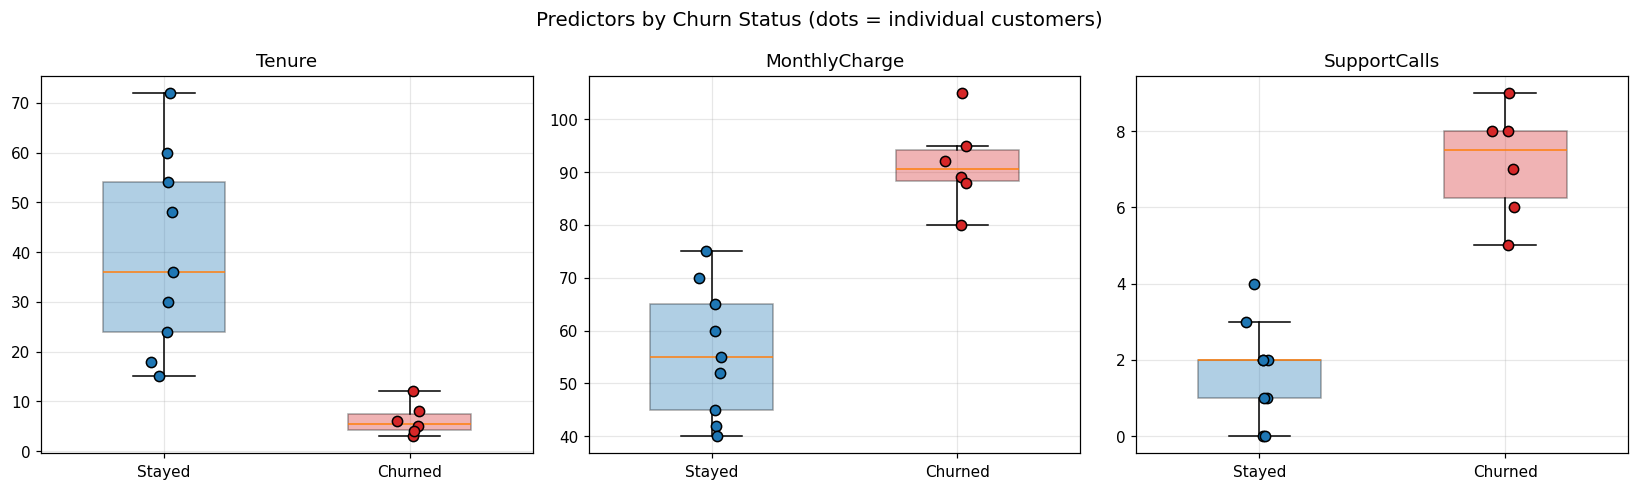

In [34]:
# distribution of each predictor by churn status
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, v in zip(axes, PREDICTORS):
    bp = ax.boxplot([df.loc[df.Churn == 0, v], df.loc[df.Churn == 1, v]], patch_artist=True, widths=0.5, showfliers=False)
    for patch, c in zip(bp["boxes"], [C_STAY, C_CHURN]):
        patch.set_facecolor(c); patch.set_alpha(0.35)
    for i, (lab, c) in enumerate([(0, C_STAY), (1, C_CHURN)], start=1):
        y = df.loc[df.Churn == lab, v]
        x = np.random.default_rng(1).normal(i, 0.04, len(y))
        ax.scatter(x, y, color=c, edgecolor="black", zorder=3, s=45)
    ax.set_xticks([1, 2], ["Stayed", "Churned"])
    ax.set_title(v)
fig.suptitle("Predictors by Churn Status (dots = individual customers)", fontsize=13)
plt.tight_layout()
plt.show()

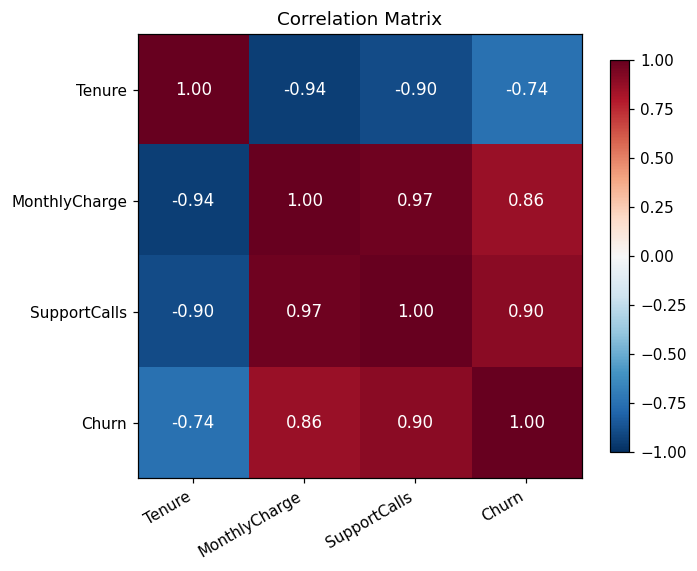

,Tenure,MonthlyCharge,SupportCalls,Churn
Tenure,1.0000,-0.9447,-0.8961,-0.7445
MonthlyCharge,-0.9447,1.0000,0.9704,0.8606
SupportCalls,-0.8961,0.9704,1.0000,0.9024
Churn,-0.7445,0.8606,0.9024,1.0000


In [35]:
# correlation heatmap
corr = df[PREDICTORS + ["Churn"]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=30, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black", fontsize=11)
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()
corr

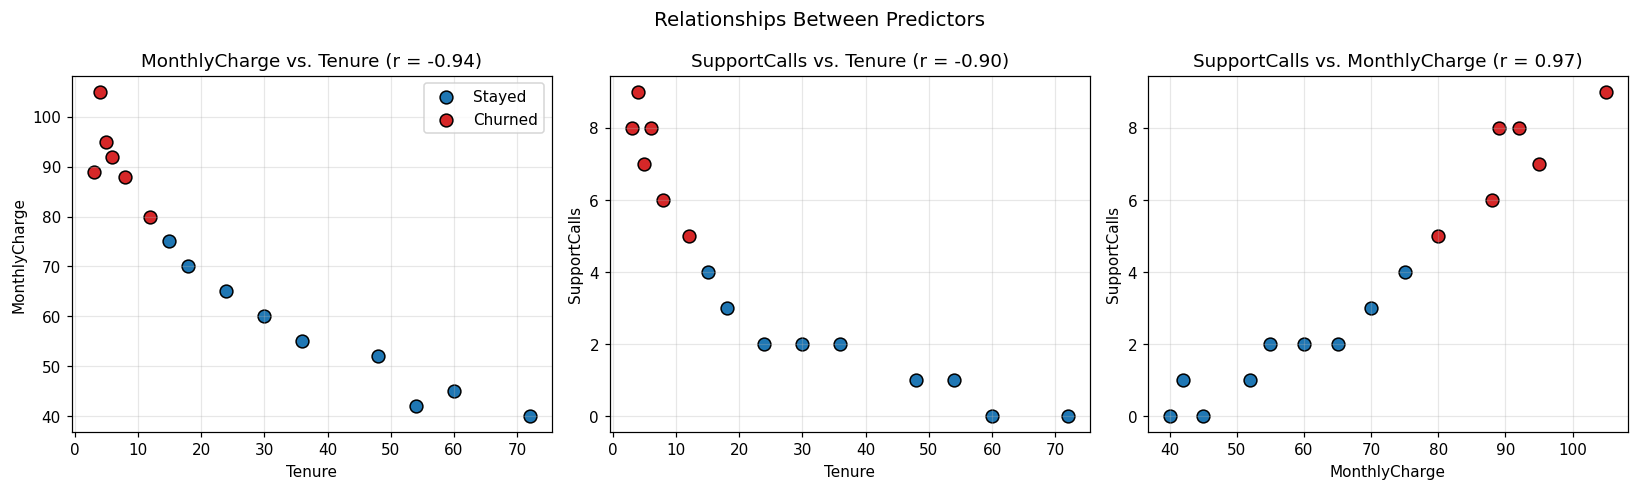

In [36]:
# pairwise scatterplots of the predictors (colored by churn)
pairs = [("Tenure", "MonthlyCharge"), ("Tenure", "SupportCalls"), ("MonthlyCharge", "SupportCalls")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (x, y) in zip(axes, pairs):
    for lab, c, name in [(0, C_STAY, "Stayed"), (1, C_CHURN, "Churned")]:
        sub = df[df.Churn == lab]
        ax.scatter(sub[x], sub[y], color=c, s=70, edgecolor="black", label=name)
    r = df[x].corr(df[y])
    ax.set_xlabel(x); ax.set_ylabel(y)
    ax.set_title(f"{y} vs. {x} (r = {r:.2f})")
axes[0].legend()
fig.suptitle("Relationships Between Predictors", fontsize=13)
plt.tight_layout()
plt.show()

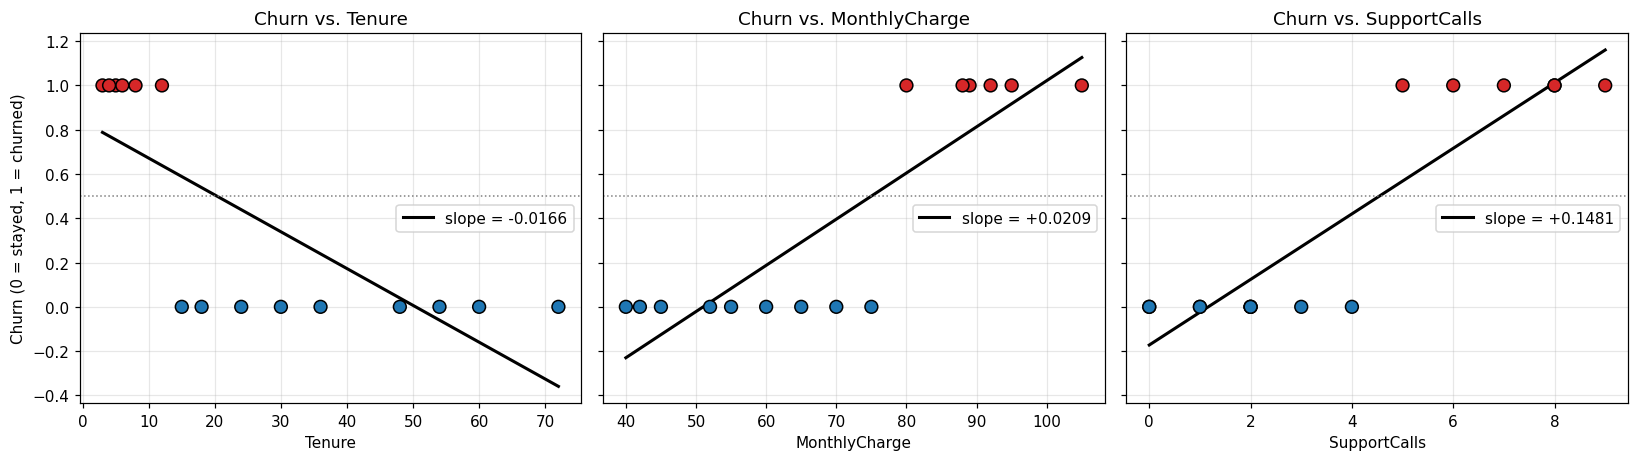

In [37]:
# churn vs. each predictor with the simple OLS line
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, v in zip(axes, PREDICTORS):
    ax.scatter(df[v], df["Churn"], c=df["Churn"].map({0: C_STAY, 1: C_CHURN}), s=70, edgecolor="black", zorder=3)
    b1, b0 = np.polyfit(df[v], df["Churn"], 1)
    xs = np.linspace(df[v].min(), df[v].max(), 100)
    ax.plot(xs, b0 + b1 * xs, color="black", lw=2, label=f"slope = {b1:+.4f}")
    ax.axhline(0.5, color="gray", ls=":", lw=1)
    ax.set_xlabel(v); ax.legend(loc="center right")
    ax.set_title(f"Churn vs. {v}")
axes[0].set_ylabel("Churn (0 = stayed, 1 = churned)")
plt.tight_layout()
plt.show()

### Is there a clean cutoff on any single variable?

If the churners and non-churners don't overlap at all on a variable, then one threshold splits them perfectly.

In [38]:
for v in PREDICTORS:
    stay, churn = df.loc[df.Churn == 0, v], df.loc[df.Churn == 1, v]
    if churn.min() > stay.max():
        print(f"{v:14s}: every churner > {stay.max()} and every non-churner <= {stay.max()}  -> perfect split")
    elif churn.max() < stay.min():
        print(f"{v:14s}: every churner <= {churn.max()} and every non-churner >= {stay.min()}  -> perfect split")
    else:
        print(f"{v:14s}: groups overlap")

Tenure        : every churner <= 12 and every non-churner >= 15  -> perfect split
MonthlyCharge : every churner > 75 and every non-churner <= 75  -> perfect split
SupportCalls  : every churner > 4 and every non-churner <= 4  -> perfect split


### Part A interpretation: patterns associated with churn

- **6 of the 15 customers (40%) churned.**
- **Churners are newer customers.** Average tenure is 6.3 months for churners vs. 39.7 months for customers who stayed. Every churner had been with the company 12 months or less, and every retained customer at least 15.
- **Churners pay more.** Average monthly charge is \$91.50 vs. \$56.00. All churners pay \$80 or more, and all retained customers pay \$75 or less.
- **Churners call support much more.** They average 7.2 calls vs. 1.7. Every churner made 5 or more calls, and no retained customer made more than 4.
- **All three differences are large and statistically significant** (Mann-Whitney p < 0.01, very large Cohen's d).
- **The predictors are strongly related to each other.** MonthlyCharge and SupportCalls have r = 0.97, and Tenure is strongly negative with both (r = -0.95 and -0.90). The data describes two clear profiles:
  **new, high-paying customers who call support a lot (churn)** vs. **long-tenured, lower-paying customers who rarely call (stay)**. This overlap matters a lot for Part B, because it will be hard to separate the effect of each variable.
- **SupportCalls has the strongest correlation with churn (r = 0.90)**, followed by MonthlyCharge (0.86) and Tenure (-0.74).

---
# Part B: Regression Modeling

## About the model

`Churn` is binary, so the OLS models below are **linear probability models**:

$$P(\text{Churn} = 1) = \beta_0 + \beta_1 X_1 + \dots + \beta_k X_k + \varepsilon$$

Each $\beta$ is the change in churn probability for a one-unit increase in that predictor, holding the others constant. The LPM is easy to interpret, but it has known weaknesses: predictions can fall outside [0, 1], and the errors are heteroskedastic by construction. So I also report heteroskedasticity-robust (HC3) standard errors, and in B.6 I look at logistic regression.

## B.1 Simple regression: picking the predictor

I fit a simple regression for each predictor and keep the one with the best fit.

In [39]:
simple_rows = []
simple_models = {}
for v in PREDICTORS:
    m = smf.ols(f"Churn ~ {v}", data=df).fit()
    simple_models[v] = m
    simple_rows.append({"Predictor": v, "Intercept": m.params["Intercept"], "Slope": m.params[v],
                        "Slope p-value": m.pvalues[v], "R²": m.rsquared, "Adj. R²": m.rsquared_adj,
                        "AIC": m.aic, "RMSE": np.sqrt(m.mse_resid)})
pd.DataFrame(simple_rows).set_index("Predictor").sort_values("R²", ascending=False)

,Intercept,Slope,Slope p-value,R²,Adj. R²,AIC,RMSE
Predictor,,,,,,,
SupportCalls,-0.1725,0.1481,0.0000,0.8143,0.8000,-0.0935,0.2268
MonthlyCharge,-1.0644,0.0209,0.0000,0.7405,0.7206,4.9236,0.2680
Tenure,0.8378,-0.0166,0.0015,0.5542,0.5199,13.0424,0.3513


SupportCalls gives the best simple model (highest R², lowest AIC), so it's my simple regression model.

## B.2 Simple regression model: Churn ~ SupportCalls

In [40]:
simple = smf.ols("Churn ~ SupportCalls", data=df).fit()
print(simple.summary())

                            OLS Regression Results                            
Dep. Variable:                  Churn   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.800
Method:                 Least Squares   F-statistic:                     57.01
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           4.19e-06
Time:                        21:03:59   Log-Likelihood:                 2.0468
No. Observations:                  15   AIC:                          -0.09350
Df Residuals:                      13   BIC:                             1.323
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -0.1725      0.096     -1.800   

In [41]:
simple_hc3 = smf.ols("Churn ~ SupportCalls", data=df).fit(cov_type="HC3")
pd.DataFrame({"Coef": simple.params, "Classic SE": simple.bse, "Classic p": simple.pvalues,
              "HC3 SE": simple_hc3.bse, "HC3 p": simple_hc3.pvalues,
              "95% CI Low": simple.conf_int()[0], "95% CI High": simple.conf_int()[1]})

,Coef,Classic SE,Classic p,HC3 SE,HC3 p,95% CI Low,95% CI High
Intercept,-0.1725,0.0958,0.0950,0.0759,0.0230,-0.3794,0.0345
SupportCalls,0.1481,0.0196,0.0000,0.0146,0.0000,0.1057,0.1904


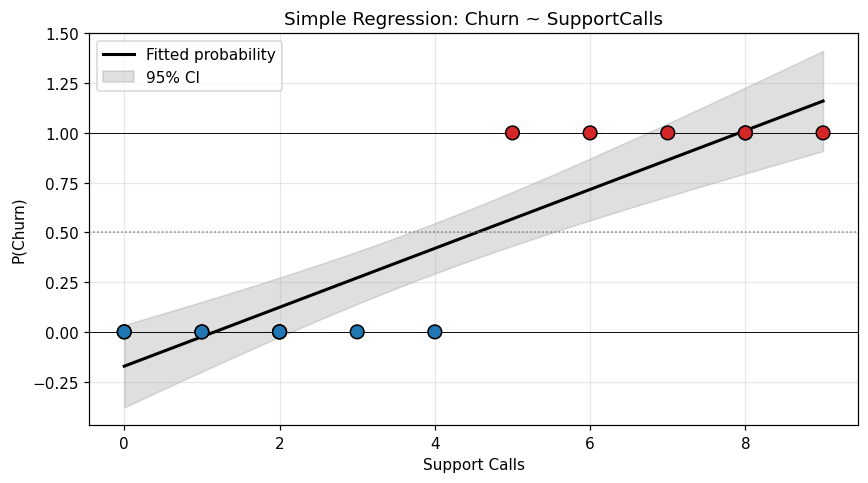

SupportCalls,0,1,2,3,4,5,6,7,8,9
Predicted P(Churn),-0.1725,-0.0244,0.1236,0.2717,0.4197,0.5678,0.7159,0.8639,1.0120,1.1600


In [42]:
# fitted line with predicted probabilities for each number of calls
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(df["SupportCalls"], df["Churn"], c=df["Churn"].map({0: C_STAY, 1: C_CHURN}),
           s=80, edgecolor="black", zorder=3)
xs = np.linspace(0, 9, 100)
pred = simple.get_prediction(pd.DataFrame({"SupportCalls": xs})).summary_frame()
ax.plot(xs, pred["mean"], color="black", lw=2, label="Fitted probability")
ax.fill_between(xs, pred["mean_ci_lower"], pred["mean_ci_upper"], color="gray", alpha=0.25, label="95% CI")
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.axhline(0, color="black", lw=0.6); ax.axhline(1, color="black", lw=0.6)
ax.set_xlabel("Support Calls"); ax.set_ylabel("P(Churn)")
ax.set_title("Simple Regression: Churn ~ SupportCalls")
ax.legend()
plt.tight_layout()
plt.show()

calls = pd.DataFrame({"SupportCalls": range(0, 10)})
calls["Predicted P(Churn)"] = simple.predict(calls)
calls.set_index("SupportCalls").T

### Simple model interpretation

- **Coefficient:** each additional support call raises the estimated churn probability by about **0.148 (≈ 15 percentage points)**. The intercept (-0.17) is the prediction for a customer with zero calls. It's slightly negative, which isn't a real probability and shows a known LPM limitation. In practice it means "very close to 0 risk". The same happens at the top end: 8 or 9 calls predict more than 100%.
- **Significance:** the slope is highly significant (t ≈ 7.55, p < 0.0001), and it stays significant with robust HC3 standard errors. The overall F-test (F ≈ 57.0) gives the same result, since there's only one predictor. The 95% CI for the slope (about 0.10 to 0.19) is well away from zero.
- **Goodness of fit:** **R² ≈ 0.81**. Support calls alone explain about 81% of the variation in churn.
- **Practical reading:** the fitted probability crosses 50% at about 4.5 calls, which matches the clean split in the data (all churners had 5+ calls, all non-churners 4 or fewer).

## B.3 Multiple regression model: Churn ~ Tenure + MonthlyCharge + SupportCalls

In [43]:
multiple = smf.ols("Churn ~ Tenure + MonthlyCharge + SupportCalls", data=df).fit()
print(multiple.summary())

                            OLS Regression Results                            
Dep. Variable:                  Churn   R-squared:                       0.838
Model:                            OLS   Adj. R-squared:                  0.794
Method:                 Least Squares   F-statistic:                     18.98
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           0.000117
Time:                        21:03:59   Log-Likelihood:                 3.0751
No. Observations:                  15   AIC:                             1.850
Df Residuals:                      11   BIC:                             4.682
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -1.0286      1.127     -0.913

In [44]:
multiple_hc3 = smf.ols("Churn ~ Tenure + MonthlyCharge + SupportCalls", data=df).fit(cov_type="HC3")
coef_tbl = pd.DataFrame({"Coef": multiple.params, "Classic SE": multiple.bse, "Classic p": multiple.pvalues,
                         "HC3 SE": multiple_hc3.bse, "HC3 p": multiple_hc3.pvalues,
                         "95% CI Low": multiple.conf_int()[0], "95% CI High": multiple.conf_int()[1]})
coef_tbl

,Coef,Classic SE,Classic p,HC3 SE,HC3 p,95% CI Low,95% CI High
Intercept,-1.0286,1.1268,0.3809,1.3571,0.4485,-3.5085,1.4514
Tenure,0.0099,0.0086,0.2702,0.0112,0.3757,-0.0089,0.0288
MonthlyCharge,0.0076,0.0171,0.6647,0.0171,0.6567,-0.0300,0.0452
SupportCalls,0.1635,0.0855,0.0821,0.0440,0.0002,-0.0246,0.3516


### Standardized coefficients

The raw coefficients are on different scales (months, dollars, calls). Standardizing all variables puts them on the same scale (change in churn, in SDs, per 1-SD change in the predictor), so we can compare them directly.

In [45]:
z = (df[PREDICTORS + ["Churn"]] - df[PREDICTORS + ["Churn"]].mean()) / df[PREDICTORS + ["Churn"]].std()
std_model = smf.ols("Churn ~ Tenure + MonthlyCharge + SupportCalls", data=z).fit()
std_tbl = pd.DataFrame({
    "Standardized beta (multiple)": std_model.params.drop("Intercept"),
    "Correlation with Churn": df[PREDICTORS].corrwith(df["Churn"]),
    "Simple-model slope": [simple_models[v].params[v] for v in PREDICTORS],
    "Multiple-model slope": multiple.params[PREDICTORS],
})
std_tbl["Sign flipped?"] = np.sign(std_tbl["Simple-model slope"]) != np.sign(std_tbl["Multiple-model slope"])
std_tbl

,Standardized beta (multiple),Correlation with Churn,Simple-model slope,Multiple-model slope,Sign flipped?
Tenure,0.4452,-0.7445,-0.0166,0.0099,True
MonthlyCharge,0.3141,0.8606,0.0209,0.0076,False
SupportCalls,0.9965,0.9024,0.1481,0.1635,False


## B.4 Multicollinearity check

The Variance Inflation Factor (VIF) measures how much a coefficient's variance is inflated by its correlation with the other predictors. VIF > 10 is usually treated as severe.

In [46]:
X = sm.add_constant(df[PREDICTORS])
vif = pd.DataFrame({"Predictor": PREDICTORS,
                    "VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(PREDICTORS))]})
vif["Severe (>10)?"] = vif["VIF"] > 10
print(f"Condition number of the design matrix: {np.linalg.cond(X.values):,.0f}\n")
vif.set_index("Predictor")

Condition number of the design matrix: 1,446



,VIF,Severe (>10)?
Predictor,,
Tenure,9.9898,False
MonthlyCharge,33.8021,True
SupportCalls,18.4368,True


## B.5 Comparing the two models

A **nested F-test** checks whether adding Tenure and MonthlyCharge to the simple model significantly improves fit. Because the sample is tiny, I also use leave-one-out cross-validation (LOOCV): fit the model on 14 customers, predict the 15th, and repeat for every customer. That shows how well each model predicts customers it hasn't seen.

In [47]:
# nested f-test: does the multiple model add anything over supportcalls alone?
print("Nested F-test (simple vs. multiple):")
print(anova_lm(simple, multiple))

Nested F-test (simple vs. multiple):
   df_resid    ssr  df_diff  ss_diff      F  Pr(>F)
0   13.0000 0.6685   0.0000      NaN    NaN     NaN
1   11.0000 0.5828   2.0000   0.0857 0.8083  0.4704


In [48]:
def loocv(formula, data):
    preds = []
    for i in data.index:
        m = smf.ols(formula, data=data.drop(index=i)).fit()
        preds.append(m.predict(data.loc[[i]]).iloc[0])
    preds = np.array(preds)
    y = data["Churn"].to_numpy()
    return {"LOOCV RMSE": np.sqrt(np.mean((y - preds) ** 2)),
            "LOOCV Accuracy (0.5 cutoff)": np.mean((preds >= 0.5) == y)}

formulas = {
    "Simple: SupportCalls": "Churn ~ SupportCalls",
    "Simple: MonthlyCharge": "Churn ~ MonthlyCharge",
    "Simple: Tenure": "Churn ~ Tenure",
    "Multiple: all three": "Churn ~ Tenure + MonthlyCharge + SupportCalls",
}
comp = []
for name, f in formulas.items():
    m = smf.ols(f, data=df).fit()
    row = {"Model": name, "R²": m.rsquared, "Adj. R²": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic,
           "F p-value": m.f_pvalue, "In-sample Accuracy": np.mean((m.fittedvalues >= 0.5) == df["Churn"])}
    row.update(loocv(f, df))
    comp.append(row)
comparison = pd.DataFrame(comp).set_index("Model")
comparison

,R²,Adj. R²,AIC,BIC,F p-value,In-sample Accuracy,LOOCV RMSE,LOOCV Accuracy (0.5 cutoff)
Model,,,,,,,,
Simple: SupportCalls,0.8143,0.8000,-0.0935,1.3226,0.0000,1.0000,0.2345,1.0000
Simple: MonthlyCharge,0.7405,0.7206,4.9236,6.3397,0.0000,0.9333,0.2781,0.9333
Simple: Tenure,0.5542,0.5199,13.0424,14.4585,0.0015,0.8667,0.3747,0.8667
Multiple: all three,0.8381,0.7939,1.8497,4.6819,0.0001,1.0000,0.2581,0.9333


### Residual diagnostics

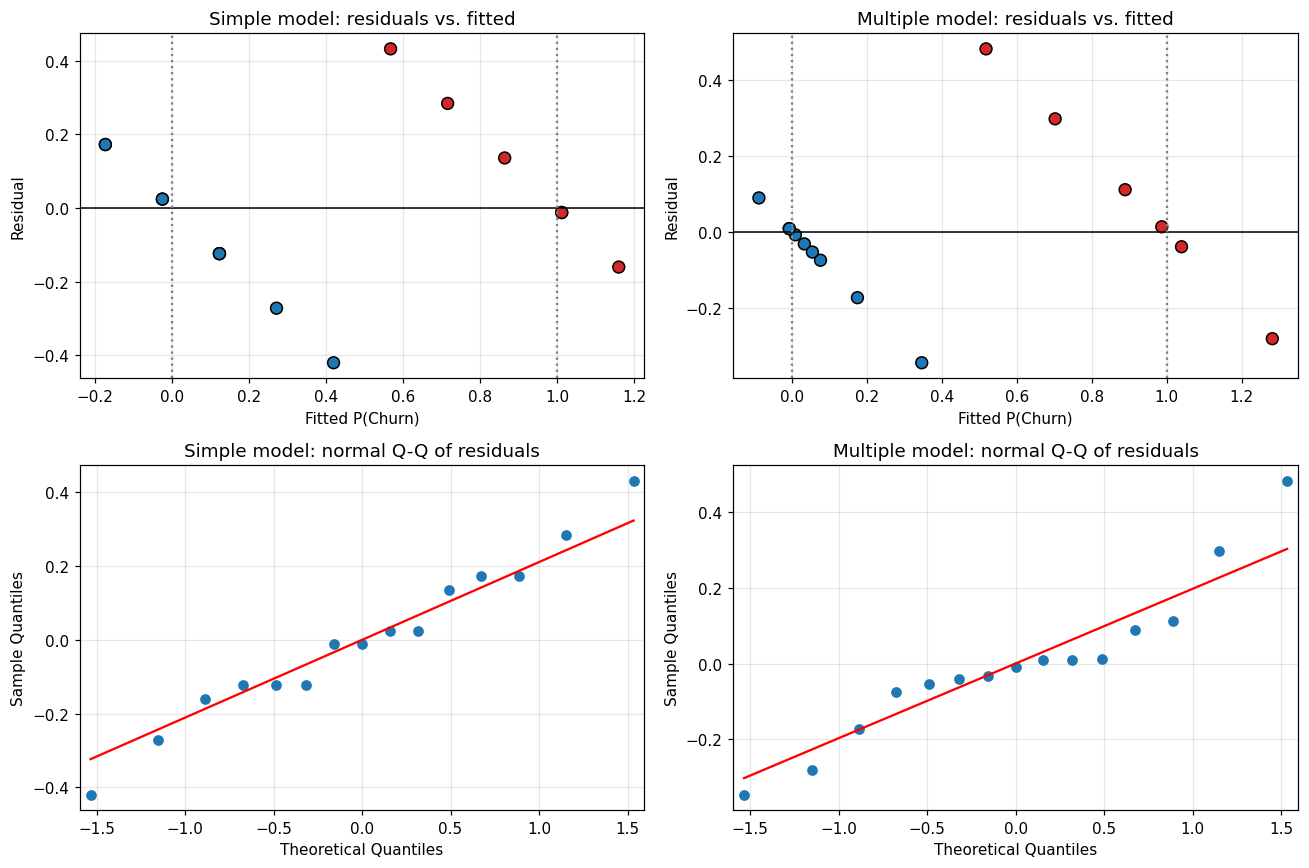

,Shapiro-Wilk p (residuals),Breusch-Pagan p,"Fitted values outside [0,1]",Max Cook's distance
Model,,,,
Simple,0.9884,0.7511,7,0.1624
Multiple,0.2526,0.3567,5,0.7515


In [49]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, (name, m) in enumerate([("Simple", simple), ("Multiple", multiple)]):
    # residuals vs. fitted
    ax = axes[0, col]
    ax.scatter(m.fittedvalues, m.resid, c=df["Churn"].map({0: C_STAY, 1: C_CHURN}), s=60, edgecolor="black")
    ax.axhline(0, color="black", lw=1)
    ax.axvline(0, color="gray", ls=":"); ax.axvline(1, color="gray", ls=":")
    ax.set_xlabel("Fitted P(Churn)"); ax.set_ylabel("Residual")
    ax.set_title(f"{name} model: residuals vs. fitted")
    # Q-Q plot
    sm.qqplot(m.resid, line="s", ax=axes[1, col])
    axes[1, col].set_title(f"{name} model: normal Q-Q of residuals")
plt.tight_layout()
plt.show()

diag = []
for name, m in [("Simple", simple), ("Multiple", multiple)]:
    out_of_range = ((m.fittedvalues < 0) | (m.fittedvalues > 1)).sum()
    diag.append({"Model": name,
                 "Shapiro-Wilk p (residuals)": stats.shapiro(m.resid).pvalue,
                 "Breusch-Pagan p": sm.stats.diagnostic.het_breuschpagan(m.resid, m.model.exog)[1],
                 "Fitted values outside [0,1]": int(out_of_range),
                 "Max Cook's distance": m.get_influence().cooks_distance[0].max()})
pd.DataFrame(diag).set_index("Model")

## B.6 Why not logistic regression?

Logistic regression is the standard model for a 0/1 outcome, so it's worth checking. But in Part A, each predictor splits churners and non-churners perfectly (complete separation). When that happens, the maximum likelihood
estimate doesn't exist: the likelihood keeps improving as the coefficient goes to infinity.

In [50]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    logit = smf.logit("Churn ~ SupportCalls", data=df).fit(disp=0, maxiter=100)
print(f"Converged: {logit.mle_retvals['converged']}")
print(f"SupportCalls coefficient: {logit.params['SupportCalls']:,.1f}  (SE = {logit.bse['SupportCalls']:,.1f})")
print(f"p-value: {logit.pvalues['SupportCalls']:.3f}")
print("\n-> The estimate is huge and meaningless and the p-value is near 1: classic perfect-separation failure.")

Converged: False
SupportCalls coefficient: 41.9  (SE = 49,699.3)
p-value: 0.999

-> The estimate is huge and meaningless and the p-value is near 1: classic perfect-separation failure.


A common fix is **penalized (L2 / ridge) logistic regression**, which shrinks coefficients and keeps them finite. I standardize the predictors so the coefficients can be compared. Since the penalty is chosen by me, these coefficients show direction and relative importance, not exact effect sizes.

In [51]:
Xs, y = df[PREDICTORS], df["Churn"]
pen = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000))
pen.fit(Xs, y)
pen_coef = pd.Series(pen[-1].coef_[0], index=PREDICTORS, name="Penalized logit coef (standardized)")
print(pen_coef.round(3), "\n")

loo_pred = []
for i in df.index:
    mdl = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000))
    mdl.fit(Xs.drop(index=i), y.drop(index=i))
    loo_pred.append(mdl.predict(Xs.loc[[i]])[0])
print(f"Penalized logistic LOOCV accuracy: {np.mean(np.array(loo_pred) == y):.0%}")

Tenure          -0.6340
MonthlyCharge    0.9430
SupportCalls     1.1160
Name: Penalized logit coef (standardized), dtype: float64 

Penalized logistic LOOCV accuracy: 93%


### Part B interpretation

**Simple model (Churn ~ SupportCalls)**
- Each extra support call adds about 15 percentage points to churn probability (p < 0.0001, robust to HC3 errors).
- **R² ≈ 0.81**, and it classifies all 15 customers correctly in sample and in leave-one-out cross-validation.

**Multiple model (Churn ~ Tenure + MonthlyCharge + SupportCalls)**
- Overall, the model is significant (F ≈ 19.0, p ≈ 0.0001) with R² ≈ 0.84 and adjusted R² ≈ 0.79.
- **But with classic standard errors, none of the individual coefficients is significant at the 5% level.** SupportCalls is closest (coef ≈ 0.16, p ≈ 0.08). Tenure (p ≈ 0.27) and MonthlyCharge (p ≈ 0.67) are far from significant. With robust HC3 standard errors, SupportCalls becomes significant (p ≈ 0.0002), while Tenure and MonthlyCharge stay insignificant (p ≈ 0.38 and 0.66). Either way, SupportCalls is the only predictor with any real evidence behind it once the others are in the model. (HC3 errors are less reliable with only 11 residual
  degrees of freedom, so I treat this as supporting evidence, not proof.)
- **Tenure's sign flips.** On its own, Tenure has a negative slope (longer tenure, lower churn). In the multiple model it turns slightly positive, which doesn't make business sense.
- This pattern (significant overall F-test, insignificant individual t-tests, flipped signs) is the textbook sign of multicollinearity, and the VIFs confirm it: about 10 for Tenure, 34 for MonthlyCharge, and 18 for supportcalls, with a very high condition number. The three predictors carry almost the same information, so the model can't tell which one deserves the credit. The coefficients become unstable, with wide confidence intervals that all include zero.

**Which model is better?**
- Adding Tenure and MonthlyCharge raises R² only from 0.81 to 0.84, and adjusted R² goes down (0.80 → 0.79).
- The nested F-test shows the two extra predictors don't significantly improve the model (F ≈ 0.81, p ≈ 0.47).
- The simple model has the lower AIC/BIC and the lower LOOCV error.
- **So the simple SupportCalls model is the better model here**: just as accurate, simpler, and its coefficient can actually be interpreted.

**Assumptions:** the residuals look roughly normal (Shapiro-Wilk p ≈ 0.99 simple, 0.25 multiple), and the Breusch-Pagan test doesn't flag heteroskedasticity, although it has little power with 15 points. The residual
plots show the striped pattern you always get with a 0/1 outcome. The bigger issue is that many fitted values fall outside [0, 1]: 7 of 15 for the simple model (customers with 0-1 calls get slightly negative probabilities,
and those with 8-9 calls get more than 100%) and 5 of 15 for the multiple model. Both are known LPM limitations. That's why I used robust standard errors and cross-checked with logistic regression. The logistic model confirms the same story. Standard logistic regression can't even be fit because of perfect separation, and the penalized version ranks Supportcalls and Monthlycharge
as the strongest churn signals, with Tenure protective.

**Caution:** with only 15 customers, all of these estimates are uncertain. The perfect separation is very likely partly a small-sample artifact, and in a larger dataset the groups would almost certainly overlap.

---
# Part C: Executive Summary

In [52]:
# key numbers for the summary computed
churn_rate = df["Churn"].mean()
means = df.groupby("Churn")[PREDICTORS].mean()
print(f"Overall churn rate: {churn_rate:.0%} ({int(df.Churn.sum())} of {len(df)})")
for v in PREDICTORS:
    print(f"{v:14s}: churned avg = {means.loc[1, v]:6.1f} | stayed avg = {means.loc[0, v]:6.1f} | "
          f"corr with churn = {df[v].corr(df['Churn']):+.2f}")
print(f"\nSimple model: +{simple.params['SupportCalls']:.3f} churn probability per support call, "
      f"R² = {simple.rsquared:.2f}, p = {simple.pvalues['SupportCalls']:.1e}")
print(f"Multiple model: R² = {multiple.rsquared:.2f} (adj. {multiple.rsquared_adj:.2f}), "
      f"overall F p = {multiple.f_pvalue:.4f}, max VIF = {vif['VIF'].max():.0f}")

Overall churn rate: 40% (6 of 15)
Tenure        : churned avg =    6.3 | stayed avg =   39.7 | corr with churn = -0.74
MonthlyCharge : churned avg =   91.5 | stayed avg =   56.0 | corr with churn = +0.86
SupportCalls  : churned avg =    7.2 | stayed avg =    1.7 | corr with churn = +0.90

Simple model: +0.148 churn probability per support call, R² = 0.81, p = 4.2e-06
Multiple model: R² = 0.84 (adj. 0.79), overall F p = 0.0001, max VIF = 34


### 1. What factors are associated with churn?

All three factors are strongly associated with churn:

| Factor | Customers who churned | Customers who stayed | Direction |
|---|---|---|---|
| Support calls | 7.2 calls on average (all had 5+) | 1.7 on average (all had 4 or fewer) | More calls → more churn |
| Monthly charge | \$91.50 on average (all \$80+) | \$56.00 on average (all \$75 or less) | Higher bill → more churn |
| Tenure | 6.3 months on average (all ≤ 12) | 39.7 months on average (all ≥ 15) | Newer customer → more churn |

The churn rate in this sample is **40%** (6 of 15). Churners fit one clear profile: new customers on expensive plans who keep calling support.

### 2. Which predictors appear most important?

1. **Support calls is the most important predictor.** It has the strongest correlation with churn (r = 0.90), gives the best single-variable model (R² = 0.81), and is the closest to significant in the multiple model. Each additional call is associated with about a 15-point increase in churn probability, and customers with 5 or more calls all churned.
2. **Monthly charge is second** (r = 0.86, R² = 0.74 on its own).
3. **Tenure is third** (r = -0.74, R² = 0.55 on its own). It's protective: longer-tenured customers stay.

**Important caveat:** the three factors are so closely linked (r up to 0.97) that the data can't fully separate their individual effects. Adding the other two variables to the support-calls model doesn't improve it in any meaningful way. Support calls likely acts as an early warning signal that captures the frustration of new, high-paying customers, not necessarily the root cause on its own.

### 3. What actions should management take?

1. **Use support calls as an early-warning trigger.** Flag any customer reaching 3-4 calls, before the 5-call level where every customer in the sample churned, and route them to a retention specialist or proactive outreach.
2. **Fix problems on the first call.** If customers are calling repeatedly, issues aren't being resolved. Track first-call resolution and the top reasons for repeat calls, and fix those root causes.
3. **Invest in the first year.** All churners left within 12 months. A structured onboarding program, check-ins at 30/60/90 days, and loyalty incentives around the 12-month mark could get customers past the risky period.
4. **Review value on high-priced plans.** Customers paying $80+ churned. Management should check whether those plans deliver enough value, and consider plan reviews, right-sizing offers, or discounts for new high-bill customers who are calling support.
5. **Collect more data before major decisions.** These findings come from only **15 customers**. Before committing large budgets, the analysis should be repeated on a larger sample, with additional variables (contract type, reason for calls, plan type, competitor offers) and an experiment (e.g., proactive outreach to half of the high-call customers) to test whether interventions actually reduce churn.

### Limitations

- **Very small sample (n = 15)**, so estimates are uncertain and the perfect separation is likely partly due to chance.
- **Association, not causation.** This is observational data; support calls may be a symptom of other problems,
  not the cause of churn.
- **Strong multicollinearity** prevents reliable estimates of each factor's individual effect.
- **The linear probability model** can produce predictions outside 0-1. Logistic regression is the usual choice and would be preferred with more data that doesn't separate perfectly.